# Dispersion-Assisted Optical Phase Recovery in Python (TDGSA)

**Python implementation:** Colin Casey, 2026
**Original project:** Gabriel Morozowsky & Colin Casey, Project Group 2, ECE 279AS *Special Topics in Physical and Wave Electronics*, Prof. Bahram Jalali, UCLA [1]

This notebook carries out the "further work" listed in the 2024 presentation: **convert to Python**, **get the code to produce good results**, and **compare number of iterations vs accuracy**. It also tests the two failure modes the presentation reported:

1. "When using a random phase guess the algorithm seemed to not want to converge."
2. Simulated parameters ($D_1$, $D_2$, fiber length) possibly not the right size.

| Section | Contents |
|---|---|
| 1 | SymPy: why a photodiode loses phase, and why dispersion brings it back |
| 2 | Physical simulation: 1550 nm pulse, causal gas-cell absorption, two dispersive measurements |
| 3 | TDGSA, plus a transport-of-intensity (TIE) initial guess |
| 4 | Results: chirped, cubic-phase, and gas-cell pulses |
| 5 | Choosing $D_1, D_2$: why the original 30/90 ps/nm pair stalls |
| 6 | Iterations vs accuracy vs time |
| 7 | Rare events: single-shot recovery flags a rogue pulse |
| 8 | Quantum information: Born rule, dispersion as a qubit circuit, GS state recovery vs shots (1 to 1e4), survival probability |
| 9 | Mapping to OUSD(R&E) Critical Technology Areas |

Kernel: **py312**.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
sp.init_printing(use_latex='mathjax')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

## 1. Why phase is lost, and how dispersion recovers it (SymPy)

A photodiode measures intensity $I(t) = |E(t)|^2$, so any phase $\varphi(t)$ drops out, just like $|\psi|^2$ in quantum mechanics.

Dispersion through a fiber is a **pure phase filter** in frequency:
$$\tilde E_{out}(\omega) = \tilde E(\omega)\, D(\omega), \qquad D(\omega) = e^{-i\beta_2 L\,\omega^2/2}, \qquad \beta_2 L = -\frac{D_{tot}\,\lambda^2}{2\pi c}$$

$|D| = 1$, so it can be undone exactly. But it mixes neighboring frequencies, so phase differences in $E$ become **intensity** changes after the fiber. Two measurements through different dispersions give two intensity "views" of the same field, linked by the known operator $D_2 D_1^{-1}$. That's the time-domain version of Gerchberg and Saxton's [2] image-plane / diffraction-plane pair.

In [2]:
w, b, phi_s = sp.symbols('omega beta_2L varphi', real=True)
D = sp.exp(-sp.I * b * w**2 / 2)
print('|D(ω)| =', sp.simplify(sp.Abs(D)))

b1, b2 = sp.symbols('beta_1L beta_2L_2', real=True)
link = sp.simplify(sp.exp(-sp.I*b2*w**2/2) / sp.exp(-sp.I*b1*w**2/2))
display(sp.Eq(sp.Symbol(r'D_2(\omega)\,D_1^{-1}(\omega)'), link))

# Unit conversion used below: beta_2 L from total dispersion in ps/nm at 1550 nm
c_, lam_, Dtot = sp.symbols('c lambda D_tot', positive=True)
b2L = -Dtot * lam_**2 / (2*sp.pi*c_)
val = b2L.subs({Dtot: sp.Rational(1, 1000), lam_: sp.Rational(155, 10**8), c_: 299792458})   # 1 ps/nm = 1e-3 s/m
print('1 ps/nm at 1550 nm  ->  β2·L =', sp.N(val * 1e24, 4), 'ps²')

# Phase is invisible to intensity: E and E·e^{iφ} have identical |E|^2
A = sp.symbols('A', positive=True)
print('|A e^{iφ}|² =', sp.simplify(sp.Abs(A*sp.exp(sp.I*phi_s))**2))

|D(ω)| = 1


                                     2                
                                  ⅈ⋅ω ⋅(β_1L - β_2L_2)
                                  ────────────────────
                                           2          
D_2(\omega)\,D_1__{-1}(\omega) = ℯ                    

1 ps/nm at 1550 nm  ->  β2·L = -1.275 ps²
|A e^{iφ}|² = A**2


### Transport of intensity (the same equation as Ch. 39 probability flow)

Dispersion obeys $i\,\partial_z A = -\tfrac{\beta_2}{2}\,\partial_t^2 A$, the free-particle Schrödinger equation [9] with $z \leftrightarrow t$ and $t \leftrightarrow x$. Writing $A = \sqrt{I}\,e^{i\varphi}$ gives a continuity equation for intensity:
$$\partial_{(\beta_2 z)} I = -\,\partial_t\!\left(I\,\partial_t \varphi\right)$$

So a **small** change in dispersion tells you $\partial_t\varphi$ directly:
$$\partial_t\varphi(t) \approx -\frac{1}{\Delta(\beta_2 L)\, I_1(t)} \int_{-\infty}^{t} \big(I_2 - I_1\big)\,dt'$$

This is the TIE [3], and it's the "good initial guess" the presentation found GS needs. SymPy check of the continuity equation:

In [3]:
t_, z = sp.symbols('t z', real=True)
Ifun, phfun = sp.Function('I')(t_, z), sp.Function('phi')(t_, z)      # both real
A_ = sp.sqrt(Ifun) * sp.exp(sp.I*phfun)
A_conj = sp.sqrt(Ifun) * sp.exp(-sp.I*phfun)
# i dA/dz + (1/2) d^2A/dt^2 = 0 (beta2 absorbed into z). Imag part of (A* x equation) gives continuity.
eq = sp.I*sp.diff(A_, z) + sp.Rational(1, 2)*sp.diff(A_, t_, 2)
expr = sp.expand(sp.powsimp(sp.expand(A_conj*eq)))
imag_part = sp.expand((expr - expr.subs(sp.I, -sp.I)) / (2*sp.I))     # all functions real, so I -> -I conjugates
continuity = sp.expand(sp.diff(Ifun, z)/2 + sp.diff(Ifun*sp.diff(phfun, t_), t_)/2)
print('Im[A* · (dispersion eq)]  equals  (∂z I + ∂t(I ∂t φ))/2 :', sp.simplify(imag_part - continuity) == 0)

Im[A* · (dispersion eq)]  equals  (∂z I + ∂t(I ∂t φ))/2 : True


## 2. Physical simulation at 1550 nm

- Laser pulse: Gaussian, $T_0 = 0.3$ ps, optional chirp $C$ and cubic phase.
- **Object under test:** a gas cell with five absorption lines, modeled as **complex Lorentzians** $H(\omega) = \prod_k \exp\!\left[-a_k / \left(1 - i(\omega-\omega_k)/\gamma_k\right)\right]$. Each factor is causal, so the absorption and phase obey **Kramers-Kronig**. The presentation listed a KK violation as a possible cause of failure.
- Grid: $2^{15}$ samples at 0.06 ps (1.97 ns window), so 5 GHz features and multi-THz bandwidth both fit.
- Ideal photodiodes (no bandwidth limit or noise unless added). See the limitations note in Section 6.

β2L for 1 ps/nm: -1.275 ps²   (pulse T0² = 0.09 ps²)


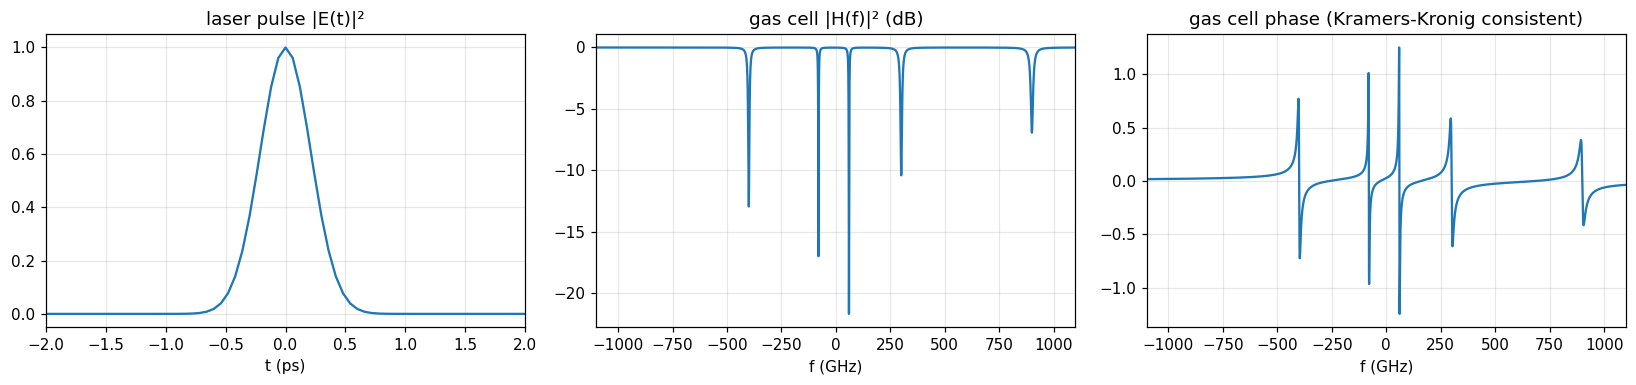

In [4]:
c, lam = 299792458.0, 1550e-9
N, dt = 2**15, 0.06e-12
t = (np.arange(N) - N//2) * dt
w = 2*np.pi*np.fft.fftfreq(N, dt)                 # baseband angular frequency (rad/s)
f_GHz = np.fft.fftshift(w) / (2*np.pi) / 1e9
T0 = 0.3e-12

def beta2L(D_ps_per_nm):
    return -D_ps_per_nm * 1e-3 * lam**2 / (2*np.pi*c)

def Dop(D_ps_per_nm):
    return np.exp(-1j * beta2L(D_ps_per_nm) * w**2 / 2)

def pulse(C=0.0, cubic=0.0):
    return np.exp(-(1 + 1j*C) * t**2 / (2*T0**2) - 1j*cubic*(t/T0)**3)

LINES = [(-400e9, 3e9, 1.5), (-80e9, 1e9, 2.0), (60e9, 1e9, 2.5), (300e9, 4e9, 1.2), (900e9, 6e9, 0.8)]  # (f0, width, strength)
H_gas = np.ones(N, complex)
for f0, g, a in LINES:
    H_gas *= np.exp(-a / (1 - 1j*(w - 2*np.pi*f0) / (2*np.pi*g)))

def measure(E0, D1, D2, noise=0.0, seed=0):
    rng = np.random.default_rng(seed)
    F = np.fft.fft(E0)
    I1 = np.abs(np.fft.ifft(F*Dop(D1)))**2
    I2 = np.abs(np.fft.ifft(F*Dop(D2)))**2
    if noise:
        I1 = I1 + noise*I1.max()*rng.standard_normal(N)
        I2 = I2 + noise*I2.max()*rng.standard_normal(N)
    return np.clip(I1, 0, None), np.clip(I2, 0, None)

E_ref = pulse()
E_gas = np.fft.ifft(np.fft.fft(E_ref) * H_gas)
print(f'β2L for 1 ps/nm: {beta2L(1)*1e24:.3f} ps²   (pulse T0² = {(T0*1e12)**2:.2f} ps²)')

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(t*1e12, np.abs(E_ref)**2); ax[0].set_xlim(-2, 2); ax[0].set_title('laser pulse |E(t)|²'); ax[0].set_xlabel('t (ps)')
ax[1].plot(f_GHz, 10*np.log10(np.abs(np.fft.fftshift(H_gas))**2)); ax[1].set_xlim(-1100, 1100)
ax[1].set_title('gas cell |H(f)|² (dB)'); ax[1].set_xlabel('f (GHz)')
ax[2].plot(f_GHz, np.unwrap(np.angle(np.fft.fftshift(H_gas)))); ax[2].set_xlim(-1100, 1100)
ax[2].set_title('gas cell phase (Kramers-Kronig consistent)'); ax[2].set_xlabel('f (GHz)')
plt.tight_layout(); plt.show()

## 3. The algorithm

**TDGSA** (presentation slide 7): start with $|f_1(t)|e^{i\varphi_1}$ → FFT → multiply by $D_2 D_1^{-1}$ → IFFT → keep the phase, replace the magnitude with measured $|f_2|$ → FFT → multiply by $D_1 D_2^{-1}$ → IFFT → replace the magnitude with measured $|f_1|$ → repeat.

**Initial phase options:** `'random'` (original GS), `'flat'` (zero), or `'tie'` (transport of intensity from Section 1).

**Error metrics:**
- *measurement error*: how well the estimate reproduces measured $|f_2|$ (this is what the presentation plotted)
- *field error*: distance to the true field after removing the unmeasurable global phase. Only possible in simulation, but it's the honest test: a low measurement error does **not** guarantee the right phase.

In [5]:
def tie_phase(I1, I2, D1, D2):
    db = beta2L(D2) - beta2L(D1)
    flux = np.cumsum(I2 - I1) * dt
    dphi = -flux / (db * (I1 + 1e-3*I1.max()))        # regularized where I1 ≈ 0
    return np.cumsum(dphi) * dt

def tdgsa(I1, I2, D1, D2, n_iter=100, init='tie', true_F=None, seed=1):
    A1, A2 = np.sqrt(I1), np.sqrt(I2)
    H12 = Dop(D2) / Dop(D1); H21 = 1 / H12
    if init == 'tie':
        phi = tie_phase(I1, I2, D1, D2)
    elif init == 'flat':
        phi = np.zeros(N)
    else:
        phi = np.random.default_rng(seed).uniform(-np.pi, np.pi, N)
    f1 = A1 * np.exp(1j*phi)
    meas_err, field_err = [], []
    for _ in range(n_iter):
        f2 = np.fft.ifft(np.fft.fft(f1) * H12)
        meas_err.append(np.linalg.norm(np.abs(f2) - A2) / np.linalg.norm(A2))
        f2 = A2 * np.exp(1j*np.angle(f2))
        f1 = np.fft.ifft(np.fft.fft(f2) * H21)
        f1 = A1 * np.exp(1j*np.angle(f1))
        if true_F is not None:
            field_err.append(field_error(np.fft.fft(f1) / Dop(D1), true_F))
    return np.fft.fft(f1) / Dop(D1), np.array(meas_err), np.array(field_err)

def align(F_rec, F_true):
    m = np.abs(F_true) > 1e-3*np.abs(F_true).max()
    g = np.vdot(F_rec[m], F_true[m]); return F_rec * g / abs(g), m

def field_error(F_rec, F_true):
    Fa, m = align(F_rec, F_true)
    return np.linalg.norm(Fa[m] - F_true[m]) / np.linalg.norm(F_true[m])

## 4. Results

Dispersion pairs are chosen per signal (Section 5 explains why). $D_1 = 0$ means the first photodiode sees the pulse undispersed.

In [6]:
CASES = {
    'chirped (C = 5)':        dict(E=pulse(C=5),       D1=0.0, D2=0.05, n=100),
    'cubic phase':            dict(E=pulse(cubic=1.0), D1=0.0, D2=0.02, n=100),
    'gas cell':               dict(E=E_gas,            D1=0.0, D2=10.0, n=300),
}
results = {}
print(f'{"case":18s} {"init":7s} {"meas err":>9s} {"field err":>10s}')
for name, cs in CASES.items():
    Ft = np.fft.fft(cs['E'])
    I1, I2 = measure(cs['E'], cs['D1'], cs['D2'])
    for init in ('random', 'flat', 'tie'):
        F, me, fe = tdgsa(I1, I2, cs['D1'], cs['D2'], cs['n'], init, true_F=Ft)
        results[(name, init)] = (F, me, fe, I1, I2)
        print(f'{name:18s} {init:7s} {me[-1]:9.2e} {fe[-1]:10.3f}')

case               init     meas err  field err


chirped (C = 5)    random   1.53e-01      1.257


chirped (C = 5)    flat     7.89e-03      0.518


chirped (C = 5)    tie      6.91e-03      0.058


cubic phase        random   6.77e-02      0.563


cubic phase        flat     7.33e-02      0.260


cubic phase        tie      5.92e-03      0.042


gas cell           random   2.99e-03      0.016


gas cell           flat     4.21e-03      0.024


gas cell           tie      3.24e-03      0.017


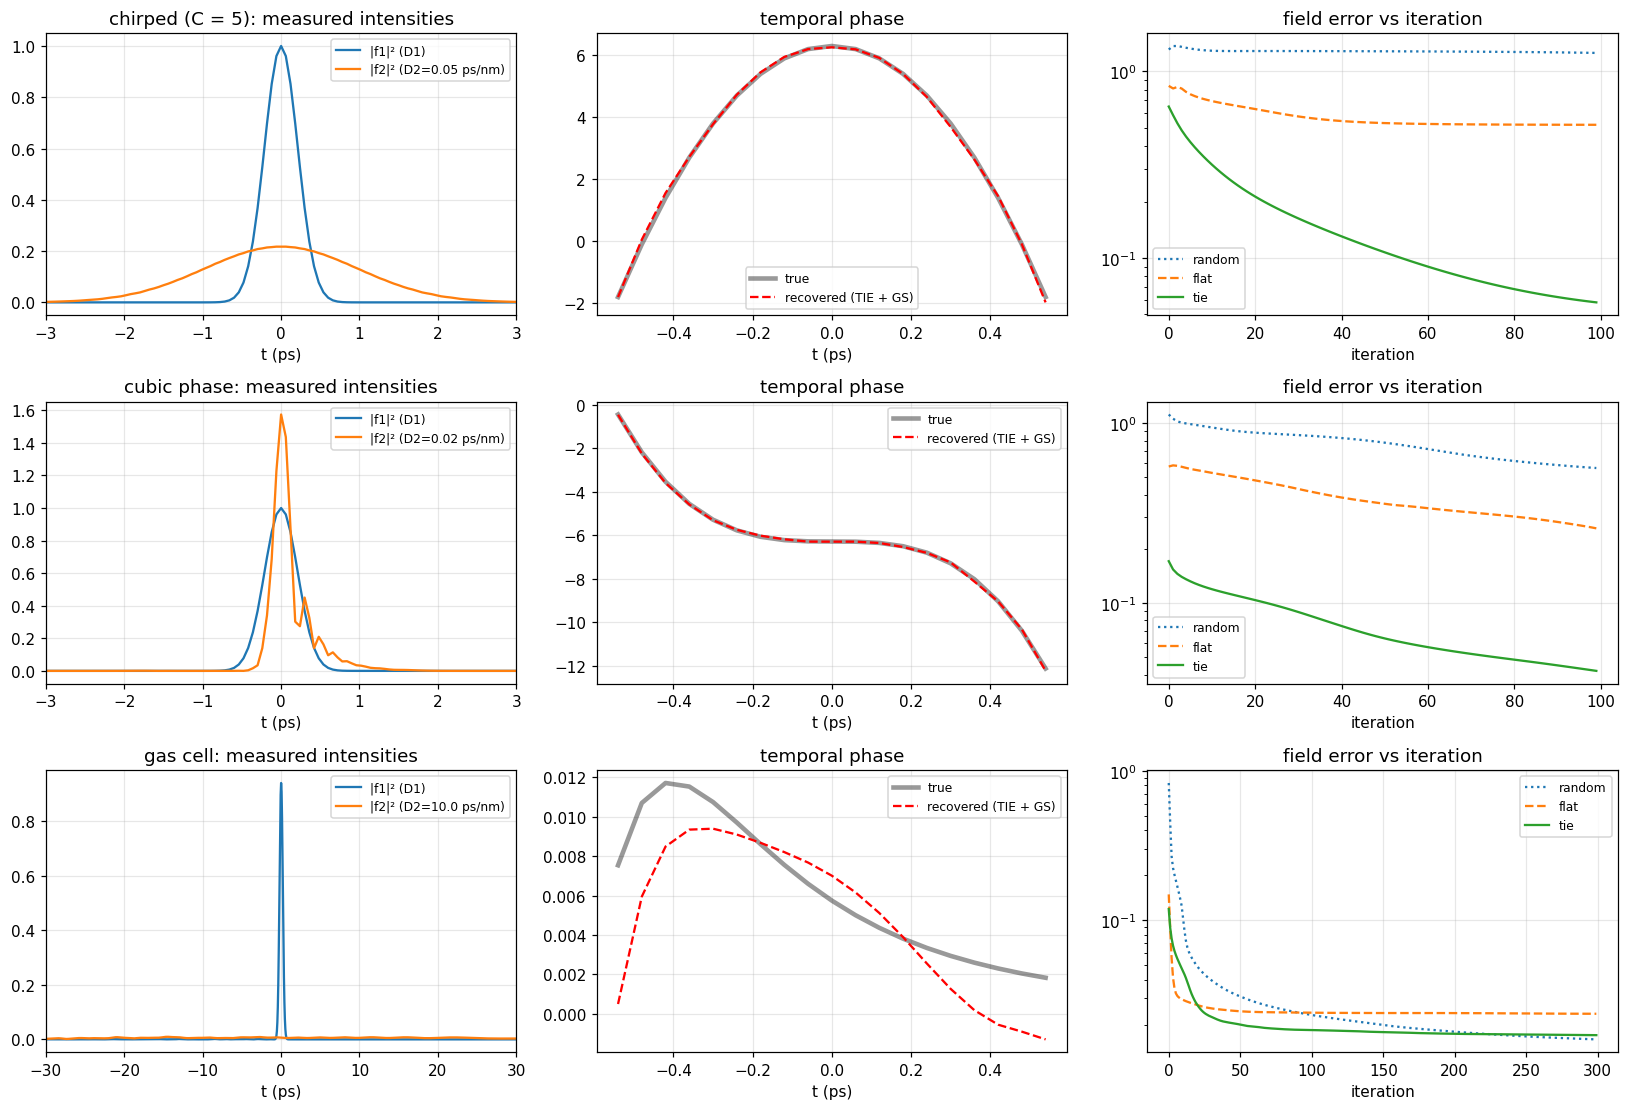

In [7]:
fig, axes = plt.subplots(len(CASES), 3, figsize=(15, 3.4*len(CASES)))
for row, (name, cs) in zip(axes, CASES.items()):
    Ft = np.fft.fft(cs['E'])
    F, me, fe, I1, I2 = results[(name, 'tie')]
    Fa, _ = align(F, Ft)
    E_rec = np.fft.ifft(Fa)
    row[0].plot(t*1e12, I1, label='|f1|² (D1)'); row[0].plot(t*1e12, I2, label=f'|f2|² (D2={cs["D2"]} ps/nm)')
    row[0].set_xlim(-30 if name == 'gas cell' else -3, 30 if name == 'gas cell' else 3); row[0].legend(fontsize=8)
    row[0].set_title(f'{name}: measured intensities'); row[0].set_xlabel('t (ps)')
    mask = np.abs(cs['E'])**2 > 0.02*np.max(np.abs(cs['E'])**2)
    row[1].plot(t[mask]*1e12, np.unwrap(np.angle(cs['E'][mask])), 'k', lw=3, alpha=0.4, label='true')
    row[1].plot(t[mask]*1e12, np.unwrap(np.angle(E_rec[mask])), 'r--', label='recovered (TIE + GS)')
    row[1].set_title('temporal phase'); row[1].set_xlabel('t (ps)'); row[1].legend(fontsize=8)
    for init, st in (('random', ':'), ('flat', '--'), ('tie', '-')):
        row[2].semilogy(results[(name, init)][2], st, label=init)
    row[2].set_title('field error vs iteration'); row[2].set_xlabel('iteration'); row[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

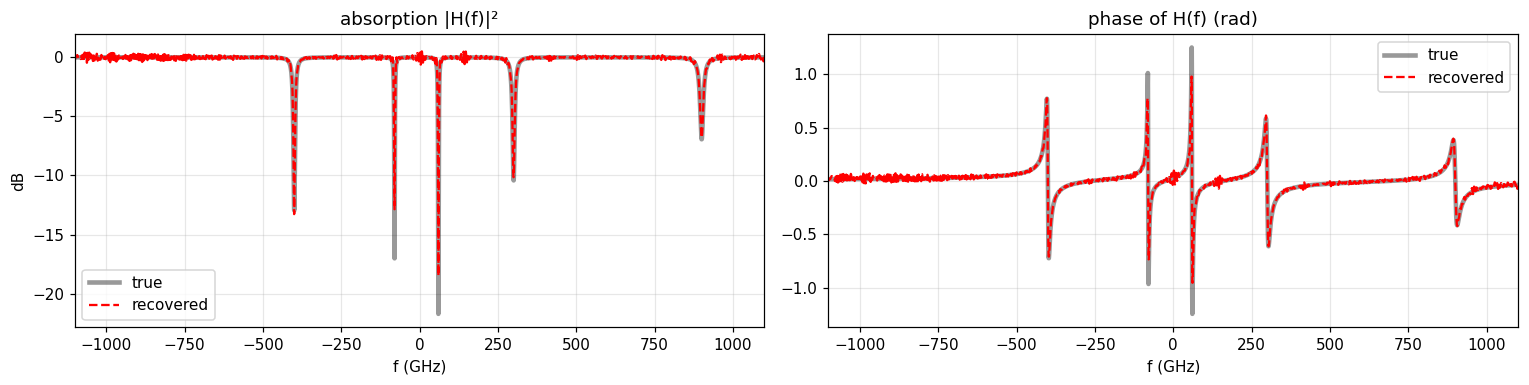

relative error in H over the pulse band: 0.01952564503584038


In [8]:
# Gas cell: recovered absorption spectrum vs truth
F, *_ = results[('gas cell', 'flat')]
P = np.fft.fft(E_ref)
Fa, _ = align(F, np.fft.fft(E_gas))
band = np.abs(P) > 0.05*np.abs(P).max()
H_rec = np.where(band, Fa / np.where(band, P, 1), np.nan)
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
ax[0].plot(f_GHz, 10*np.log10(np.abs(np.fft.fftshift(H_gas))**2), 'k', lw=3, alpha=0.4, label='true')
ax[0].plot(f_GHz, 10*np.log10(np.abs(np.fft.fftshift(H_rec))**2), 'r--', label='recovered')
ax[0].set_xlim(-1100, 1100); ax[0].set_ylabel('dB'); ax[0].set_title('absorption |H(f)|²'); ax[0].legend()
ax[1].plot(f_GHz, np.angle(np.fft.fftshift(H_gas)), 'k', lw=3, alpha=0.4, label='true')
ax[1].plot(f_GHz, np.angle(np.fft.fftshift(H_rec)), 'r--', label='recovered')
ax[1].set_xlim(-1100, 1100); ax[1].set_title('phase of H(f) (rad)'); ax[1].legend()
for a_ in ax: a_.set_xlabel('f (GHz)')
plt.tight_layout(); plt.show()
print('relative error in H over the pulse band:', np.nanmean(np.abs(H_rec[band] - H_gas[band])) / np.mean(np.abs(H_gas[band])))

## 5. Choosing $D_1, D_2$: why 30 / 90 ps/nm stalls

With $\beta_2 L \approx 1.28\ \text{ps}^2$ per ps/nm and $T_0^2 = 0.09\ \text{ps}^2$, 30 and 90 ps/nm put **both** measurements deep in the far field (stretch factor ≈ 400 and ≈ 1300). In the far field, the intensity is just a scaled copy of $|\tilde E(\omega)|^2$ (the dispersive Fourier transform [4]). Both photodiodes then record nearly the **same** information, and the spectral phase is left almost unconstrained.

Rule of thumb from the sweep below:
- One measurement near the source ($D_1 \approx 0$).
- $D_2$ large enough that $\beta_2 L$ is comparable to the **squared time scale of the feature you want**: about $T_0^2$ for a chirped pulse, but $(1/\text{linewidth})^2$-ish for narrow gas lines, which need much more stretch.

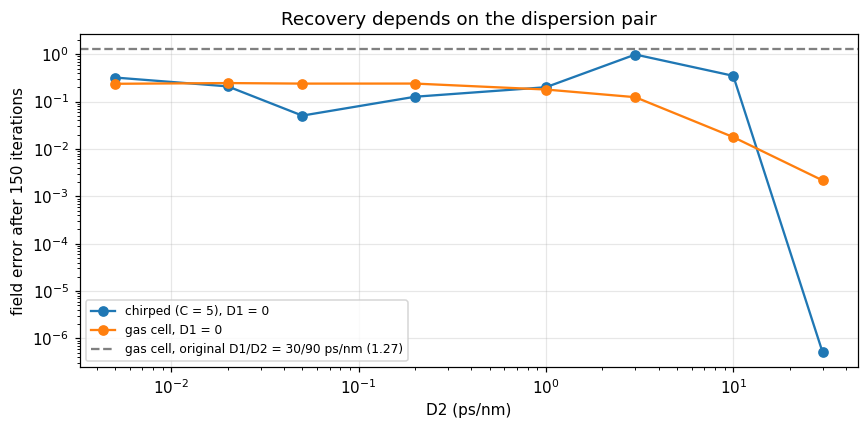

In [9]:
D2_list = [0.005, 0.02, 0.05, 0.2, 1, 3, 10, 30]
sweep = {name: [] for name in ('chirped (C = 5)', 'gas cell')}
for name in sweep:
    E0 = CASES[name]['E']; Ft = np.fft.fft(E0)
    for D2 in D2_list:
        I1, I2 = measure(E0, 0.0, D2)
        F, *_ = tdgsa(I1, I2, 0.0, D2, 150, 'tie')
        sweep[name].append(field_error(F, Ft))
I1, I2 = measure(E_gas, 30.0, 90.0)
F, *_ = tdgsa(I1, I2, 30.0, 90.0, 150, 'tie')
orig = field_error(F, np.fft.fft(E_gas))

plt.figure(figsize=(8, 4))
for name, errs in sweep.items():
    plt.semilogx(D2_list, errs, 'o-', label=f'{name}, D1 = 0')
plt.axhline(orig, color='gray', ls='--', label=f'gas cell, original D1/D2 = 30/90 ps/nm ({orig:.2f})')
plt.xlabel('D2 (ps/nm)'); plt.ylabel('field error after 150 iterations'); plt.yscale('log'); plt.legend(fontsize=8)
plt.title('Recovery depends on the dispersion pair'); plt.tight_layout(); plt.show()

## 6. Iterations vs accuracy vs time

The 2024 presentation timed MATLAB on an i7-9750H. Here: the same iteration counts on the gas-cell case (field error is available because this is a simulation).

In [10]:
I1, I2 = measure(E_gas, 0.0, 10.0)
Ft = np.fft.fft(E_gas)
rows = []
for n in (1, 10, 100, 1000, 10_000):
    t0 = time.perf_counter()
    F, me, _ = tdgsa(I1, I2, 0.0, 10.0, n, 'flat')
    rows.append((n, 1e3*(time.perf_counter() - t0), me[-1], field_error(F, Ft)))
print(f'{"iterations":>10s} {"time (ms)":>10s} {"meas err":>10s} {"field err":>10s}')
for r in rows:
    print(f'{r[0]:10d} {r[1]:10.1f} {r[2]:10.2e} {r[3]:10.3f}')

# Noise robustness
print('\nphotodiode noise (fraction of peak) -> field error, 300 iterations')
for nz in (0, 1e-4, 1e-3, 1e-2):
    I1n, I2n = measure(E_gas, 0.0, 10.0, noise=nz)
    F, *_ = tdgsa(I1n, I2n, 0.0, 10.0, 300, 'flat')
    print(f'  {nz:7.0e}  ->  {field_error(F, Ft):.3f}')

iterations  time (ms)   meas err  field err
         1       12.0   1.64e-01      0.149
        10       53.2   8.33e-03      0.030
       100      626.6   4.69e-03      0.024
      1000     5646.5   4.01e-03      0.023
     10000    70869.4   3.74e-03      0.022

photodiode noise (fraction of peak) -> field error, 300 iterations


    0e+00  ->  0.024


    1e-04  ->  0.176


    1e-03  ->  0.557


    1e-02  ->  1.833


**Limitations (honest):**

- **Noise:** the field error grows fast with photodiode noise (table above). The TIE start divides by a small dispersion difference, which amplifies noise, and the 2 ns window holds thousands of noise-only samples for a sub-ps pulse. Section 7 is therefore noise-free. Denoising, a tighter window, or more than two dispersion planes are the obvious next steps.
- **Bandwidth:** the photodiodes here have unlimited bandwidth. A real $D_1 = 0$ measurement of a 0.3 ps pulse is impossible with a photodiode (tens of GHz at best). That's the reason time stretch exists. A realistic next step is to add a detector bandwidth filter to $I_1, I_2$ and re-run the $D_1, D_2$ sweep with both values large enough for the detector, but chosen to stay out of the redundant far-field regime.

## 7. Rare events: single-shot recovery catches a rogue pulse

Time stretch made it possible to record *every* pulse in real time [6]. That's how Jalali's group observed **optical rogue waves**, rare extreme events hidden in averaged measurements [5]. Here: 80 noise-free laser shots with small random chirp jitter, plus one rogue shot ($C = 7.5$). TDGSA ($D_2 = 0.02$ ps/nm, TIE start, 60 iterations) recovers each shot's phase, a quadratic fit gives each shot's chirp, and a robust z-score flags outliers.

80 shots in 38.7 s (484 ms/shot)
flagged shots: [57]   (true rogue shot: 57 )
chirp estimate RMS error (normal shots): 0.145


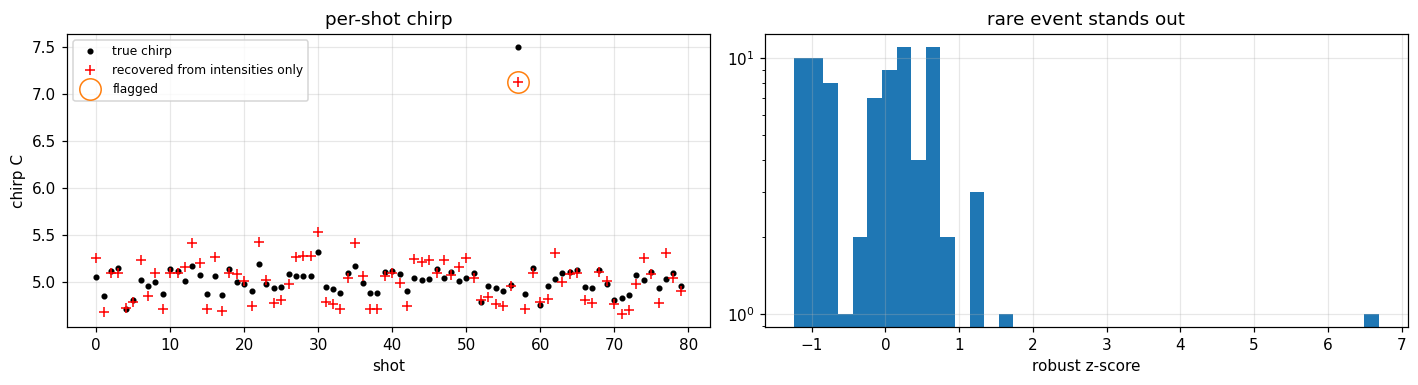

In [11]:
rng = np.random.default_rng(42)
n_shots, rogue = 80, 57
C_true = rng.normal(5.0, 0.15, n_shots); C_true[rogue] = 7.5
core = np.abs(t) < 1.5*T0
C_est = np.empty(n_shots)
t0 = time.perf_counter()
for i, C in enumerate(C_true):
    E0 = pulse(C=C)
    I1, I2 = measure(E0, 0.0, 0.02)
    F, *_ = tdgsa(I1, I2, 0.0, 0.02, 60, 'tie')
    ph = np.unwrap(np.angle(np.fft.ifft(F)[core]))
    a2 = np.polyfit(t[core] / T0, ph, 2)[0]          # phase = -C (t/T0)^2 / 2
    C_est[i] = -2 * a2
elapsed = time.perf_counter() - t0
med = np.median(C_est); mad = 1.4826*np.median(np.abs(C_est - med))
z = (C_est - med) / mad
flag = np.where(np.abs(z) > 5)[0]
print(f'{n_shots} shots in {elapsed:.1f} s ({1e3*elapsed/n_shots:.0f} ms/shot)')
print('flagged shots:', flag.tolist(), '  (true rogue shot:', rogue, ')')
print(f'chirp estimate RMS error (normal shots): {np.sqrt(np.mean(np.delete(C_est - C_true, rogue)**2)):.3f}')

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].plot(C_true, 'k.', label='true chirp'); ax[0].plot(C_est, 'r+', label='recovered from intensities only')
ax[0].plot(flag, C_est[flag], 'o', mfc='none', ms=14, color='C1', label='flagged'); ax[0].legend(fontsize=8)
ax[0].set_xlabel('shot'); ax[0].set_ylabel('chirp C'); ax[0].set_title('per-shot chirp')
ax[1].hist(z, bins=40); ax[1].set_yscale('log'); ax[1].set_xlabel('robust z-score'); ax[1].set_title('rare event stands out')
plt.tight_layout(); plt.show()

## 8. Quantum link: Born rule, QFT, and Qiskit

A qubit measurement gives probabilities $|\langle k|\psi\rangle|^2$. The **phase is lost**, exactly like the photodiode. Applying a known unitary before measuring (a quantum Fourier transform, or in optics a dispersive fiber) turns phase differences into measurable probability differences.

Below: two states with identical computational-basis probabilities but different phases. Direct measurement can't tell them apart; after a QFT they differ. NumPy statevectors first, then the same thing in Qiskit [8].

In [12]:
n_q = 3; dim = 2**n_q
amp = np.ones(dim) / np.sqrt(dim)
psi_a = amp.astype(complex)
psi_b = amp * np.exp(1j * 2*np.pi * 2 * np.arange(dim) / dim)      # hidden linear phase
QFT = np.exp(2j*np.pi*np.outer(np.arange(dim), np.arange(dim)) / dim) / np.sqrt(dim)
print('direct measurement probs a:', np.round(np.abs(psi_a)**2, 3))
print('direct measurement probs b:', np.round(np.abs(psi_b)**2, 3), ' <- identical: phase invisible')
print('after QFT, probs a:', np.round(np.abs(QFT @ psi_a)**2, 3))
print('after QFT, probs b:', np.round(np.abs(QFT @ psi_b)**2, 3), ' <- phase now visible')

try:
    from qiskit import QuantumCircuit
    from qiskit.circuit.library import QFTGate
    from qiskit.quantum_info import Statevector
    qc = QuantumCircuit(n_q); qc.prepare_state(Statevector(psi_b), range(n_q)); qc.append(QFTGate(n_q), range(n_q))
    print('Qiskit QFTGate on b:     ', np.round(Statevector(qc).probabilities(), 3))
except ImportError:
    print('(Qiskit not installed in this kernel; NumPy result above is the same math.)')

direct measurement probs a: [0.125 0.125 0.125 0.125 0.125 0.125 0.125 0.125]
direct measurement probs b: [0.125 0.125 0.125 0.125 0.125 0.125 0.125 0.125]  <- identical: phase invisible
after QFT, probs a: [1. 0. 0. 0. 0. 0. 0. 0.]
after QFT, probs b: [0. 0. 0. 0. 0. 0. 1. 0.]  <- phase now visible


Qiskit QFTGate on b:      [0. 0. 0. 0. 0. 0. 1. 0.]


### 8b. Dispersion as a quantum circuit, and Gerchberg-Saxton on qubits

On $n$ qubits, the same dispersion operator is a circuit:
$$D(a) = \mathrm{QFT}^{-1}\;\mathrm{diag}\!\left(e^{-i a k_j^2}\right)\;\mathrm{QFT}$$
This is the discrete free-particle propagator (a quantum walk / quantum simulation of Schrödinger evolution [9]).

**Quantum phase retrieval:** prepare an unknown 6-qubit state $|\psi\rangle$ (a chirped wave packet), measure in the computational basis with no dispersion ($a_1=0$) and after $D(a_2)$. Those two probability histograms are exactly the two photodiode traces of TDGSA. Run the same GS loop to recover the complex amplitudes, then score with the **state fidelity** $|\langle\psi_{rec}|\psi\rangle|^2$.

Real quantum hardware gives counts, not exact probabilities, so the sweep uses **1, 10, 100, 1000, 10⁴ shots**.

In [13]:
from qiskit import QuantumCircuit
from qiskit.circuit.library import QFTGate, DiagonalGate
from qiskit.quantum_info import Statevector, state_fidelity
from qiskit.primitives import StatevectorSampler
import qiskit
print('Qiskit', qiskit.__version__)

nq = 6; dimq = 2**nq
kq = 2*np.pi*np.fft.fftfreq(dimq)
xq = np.arange(dimq) - dimq//2

def disp_circuit(a):
    qc = QuantumCircuit(nq)
    qc.append(QFTGate(nq), range(nq))
    qc.append(DiagonalGate(list(np.exp(-1j*a*kq**2))), range(nq))
    qc.append(QFTGate(nq).inverse(), range(nq))
    return qc

def D_np(a, v):                     # same operator in NumPy (Qiskit's QFT is the e^{+i} transform)
    return np.fft.fft(np.fft.ifft(v, norm='ortho') * np.exp(-1j*a*kq**2), norm='ortho')

psi_q = np.roll(np.exp(-xq**2/(4*2.0**2) + 1j*0.15*xq**2/4), dimq//2)
psi_q /= np.linalg.norm(psi_q)

def prepared(a):
    qc = QuantumCircuit(nq); qc.prepare_state(Statevector(psi_q), range(nq))
    return qc.compose(disp_circuit(a))

print('circuit vs NumPy operator, max diff:', np.abs(Statevector(prepared(3.0)).data - D_np(3.0, psi_q)).max())
print('gate counts after decomposition:', dict(disp_circuit(3.0).decompose(reps=2).count_ops()))

Qiskit 2.5.2
circuit vs NumPy operator, max diff: 1.3365039024253451e-11
gate counts after decomposition: {'p': 90, 'cx': 78, 'u': 12, 'circuit-115': 1, 'circuit-134': 1, 'circuit-138': 1, 'circuit-142': 1, 'circuit-146': 1, 'circuit-150': 1}


  shots  mean fidelity     std
      1         0.1070  0.0658
     10         0.5668  0.1110
    100         0.9547  0.0077
   1000         0.9905  0.0021
  10000         0.9985  0.0014
  exact         1.0000


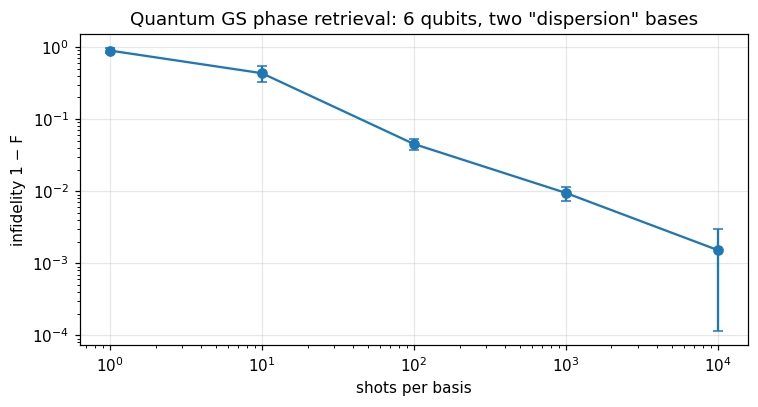

In [14]:
A1_Q, A2_Q = 0.0, 4.0

def measured_probs(a, shots, seed):
    if shots is None:
        return Statevector(prepared(a)).probabilities()
    qc = prepared(a); qc.measure_all()
    counts = StatevectorSampler(seed=seed).run([qc], shots=shots).result()[0].data.meas.get_int_counts()
    p = np.zeros(dimq)
    for j, c_ in counts.items(): p[j] = c_
    return p / shots

def gs_qubits(P1, P2, iters=300):
    A1, A2 = np.sqrt(P1), np.sqrt(P2)
    f = A1.astype(complex)
    for _ in range(iters):
        g = D_np(A2_Q - A1_Q, f); g = A2 * np.exp(1j*np.angle(g))
        f = D_np(A1_Q - A2_Q, g); f = A1 * np.exp(1j*np.angle(f))
    return f / np.linalg.norm(f)

shot_list = [1, 10, 100, 1000, 10_000]
fid = {s_: [] for s_ in shot_list}
for s_ in shot_list:
    for seed in range(8):
        P1 = measured_probs(A1_Q, s_, seed); P2 = measured_probs(A2_Q, s_, 100 + seed)
        fid[s_].append(state_fidelity(Statevector(gs_qubits(P1, P2)), Statevector(psi_q)))
exact = state_fidelity(Statevector(gs_qubits(measured_probs(A1_Q, None, 0), measured_probs(A2_Q, None, 0))), Statevector(psi_q))

print(f'{"shots":>7s} {"mean fidelity":>14s} {"std":>7s}')
for s_ in shot_list:
    print(f'{s_:7d} {np.mean(fid[s_]):14.4f} {np.std(fid[s_]):7.4f}')
print(f'{"exact":>7s} {exact:14.4f}')

plt.figure(figsize=(7, 3.8))
plt.errorbar(shot_list, [1 - np.mean(fid[s_]) for s_ in shot_list], yerr=[np.std(fid[s_]) for s_ in shot_list], fmt='o-', capsize=3)
plt.xscale('log'); plt.yscale('log'); plt.xlabel('shots per basis'); plt.ylabel('infidelity 1 − F')
plt.title('Quantum GS phase retrieval: 6 qubits, two "dispersion" bases'); plt.tight_layout(); plt.show()

### 8c. Survival probability ("chance of survival")

The **survival probability** is the chance a system is still found in its starting state: $P(a) = |\langle\psi_0|D(a)|\psi_0\rangle|^2$. For a Gaussian packet of width $\sigma$, SymPy gives a closed form below. Two features:

- **Short times:** $1 - P \propto a^2$ (quadratic, not linear). This is the origin of the quantum Zeno effect: measuring often freezes the state.
- **Long times:** $P \propto 1/a$. Spreading makes the overlap decay slowly. In the fiber, $a = \beta_2 L/2$, so $P$ says how far a pulse can travel before dispersion makes it "a different pulse", which also sets how much dispersion TDGSA needs.

               2     
            2⋅σ      
P(a) = ──────────────
          ___________
         ╱  2      4 
       ╲╱  a  + 4⋅σ  

short-time series:


      2         
     a      ⎛ 3⎞
1 - ──── + O⎝a ⎠
       4        
    8⋅σ         

Qiskit survival at a = 5: 0.8479983040051079   formula: 0.847998304005088


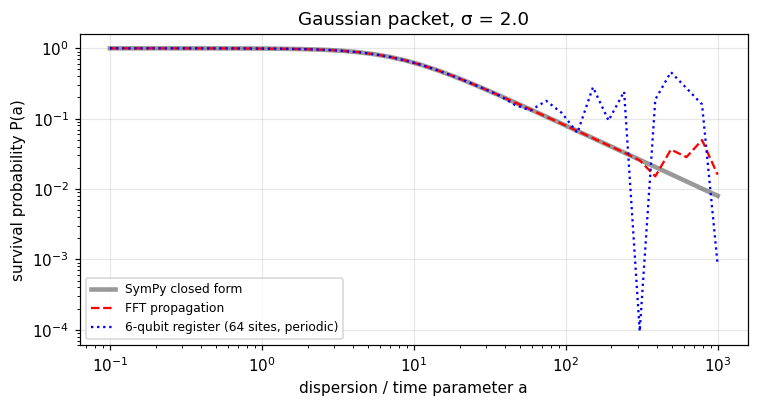

In [15]:
kk, a_s, sg = sp.symbols('k a sigma', positive=True)
# |psi0~(k)|^2 ∝ exp(-2 sigma^2 k^2); amplitude = <exp(-i a k^2)> under that weight
# Gaussian integral ∫exp(-c k²)dk = sqrt(pi/c); do it with c > 0, then continue c -> 2σ² + i a
c_g = sp.symbols('c', positive=True)
ratio = sp.integrate(sp.exp(-c_g*kk**2), (kk, -sp.oo, sp.oo)) / sp.integrate(sp.exp(-2*sg**2*kk**2), (kk, -sp.oo, sp.oo))
amp = sp.simplify(ratio).subs(c_g, 2*sg**2 + sp.I*a_s)            # sqrt(2σ² / (2σ² + i a))
P_surv = sp.simplify(sp.sqrt(sp.simplify(amp**2 * sp.conjugate(amp**2))))
display(sp.Eq(sp.Symbol('P(a)'), P_surv))
print('short-time series:'); display(sp.series(P_surv, a_s, 0, 3))

# numeric checks: continuous FFT grid (Section 2) and the 6-qubit register
sig_x = 2.0
xg_ = np.linspace(-200, 200, 8192, endpoint=False); kg_ = 2*np.pi*np.fft.fftfreq(xg_.size, xg_[1]-xg_[0])
psi0 = np.exp(-xg_**2/(4*sig_x**2)); psi0 /= np.linalg.norm(psi0)
P_f = sp.lambdify(a_s, P_surv.subs(sg, sig_x))
a_vals = np.logspace(-1, 3, 40)
P_fft = [abs(np.vdot(psi0, np.fft.ifft(np.fft.fft(psi0)*np.exp(-1j*a_*kg_**2))))**2 for a_ in a_vals]
psi_g6 = np.roll(np.exp(-xq**2/(4*sig_x**2)), dimq//2); psi_g6 /= np.linalg.norm(psi_g6)
P_qb = [abs(np.vdot(psi_g6, D_np(a_, psi_g6)))**2 for a_ in a_vals]   # verified equal to the circuit above
qc_chk = QuantumCircuit(nq); qc_chk.prepare_state(Statevector(psi_g6), range(nq)); qc_chk.compose(disp_circuit(5.0), inplace=True)
print('Qiskit survival at a = 5:', abs(np.vdot(psi_g6, Statevector(qc_chk).data))**2, '  formula:', float(P_f(5.0)))

plt.figure(figsize=(7, 3.8))
plt.loglog(a_vals, [float(P_f(a_)) for a_ in a_vals], 'k', lw=3, alpha=0.4, label='SymPy closed form')
plt.loglog(a_vals, P_fft, 'r--', label='FFT propagation')
plt.loglog(a_vals, P_qb, 'b:', label='6-qubit register (64 sites, periodic)')
plt.xlabel('dispersion / time parameter a'); plt.ylabel('survival probability P(a)'); plt.legend(fontsize=8)
plt.title(f'Gaussian packet, σ = {sig_x}'); plt.tight_layout(); plt.show()

On 64 periodic sites the qubit curve follows the formula until the packet wraps around the register, then shows **revivals** (the discrete-system version of the Talbot effect), which an infinite fiber never has.

## 9. OUSD(R&E) Critical Technology Areas [7]

The areas marked on the CTA list, and how this work relates. Fit strength is my own assessment.

| Critical Technology Area | Connection | Fit |
|---|---|---|
| **FutureG** | Carrier-less coherent receiver: recover phase without a local oscillator, cutting power, size and cost (presentation slide 14) | strong |
| **Integrated Sensing and Cyber** | Single-shot gas spectroscopy (Section 4) and real-time detection of rare events (Section 7) | strong |
| **Advanced Computing and Software** | FFT-based iterative solver; the iteration-count vs time trade-off (Section 6) decides whether it can run at line rate | medium |
| **Trusted AI and Autonomy** | Physics-based recovery is deterministic and checkable (field error, measurement error), a baseline to compare ML phase recovery against | medium |
| **Directed Energy** | Pulse phase/chirp diagnostics for high-power lasers (Section 7 measures chirp per shot) | weak to medium |
| **Human-Machine Interfaces** | Interactive notebook / visualization of the measurements only | weak |

## References

[1] G. Morozowsky and C. Casey, "Dispersion assisted optical phase recovery," presented at ECE 279AS, Univ. of California, Los Angeles, CA, USA, Mar. 13, 2024 (unpublished course presentation).

[2] R. W. Gerchberg and W. O. Saxton, "A practical algorithm for the determination of phase from image and diffraction plane pictures," *Optik*, vol. 35, no. 2, pp. 237–246, 1972.

[3] M. R. Teague, "Deterministic phase retrieval: A Green's function solution," *J. Opt. Soc. Am.*, vol. 73, no. 11, pp. 1434–1441, 1983, doi: 10.1364/JOSA.73.001434.

[4] K. Goda and B. Jalali, "Dispersive Fourier transformation for fast continuous single-shot measurements," *Nature Photon.*, vol. 7, no. 2, pp. 102–112, 2013, doi: 10.1038/nphoton.2012.359.

[5] D. R. Solli, C. Ropers, P. Koonath, and B. Jalali, "Optical rogue waves," *Nature*, vol. 450, no. 7172, pp. 1054–1057, 2007, doi: 10.1038/nature06402.

[6] A. Mahjoubfar, D. V. Churkin, S. Barland, N. Broderick, S. K. Turitsyn, and B. Jalali, "Time stretch and its applications," *Nature Photon.*, vol. 11, no. 6, pp. 341–351, 2017, doi: 10.1038/nphoton.2017.76.

[7] Office of the Under Secretary of Defense for Research and Engineering, "Critical technology areas," U.S. Dept. of Defense, Washington, DC, USA, 2022.

[8] Qiskit contributors, "Qiskit: An open-source framework for quantum computing," 2023, doi: 10.5281/zenodo.2573505.

[9] D. J. Griffiths and D. F. Schroeter, *Introduction to Quantum Mechanics*, 3rd ed. Cambridge, U.K.: Cambridge Univ. Press, 2018.